<a href="https://colab.research.google.com/github/gulgom1227-coder/2026_2S_phonology/blob/main/06_Speech_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Audio Processing

## 1. Waveform

In [1]:
# Import packages
import librosa
import numpy as np
import matplotlib.pyplot as plt

#음성은 숫자 데이터

In [9]:
# Load audio
audio, sr = librosa.load("aeiou.wav")

print(audio.shape) # 개수가 48600개니 즉 약 2초쯤 될거임
print(sr) # sampling의 개수 출력 (librosa 기본 22050Hz)
len(audio) #1차원 데이터니 len사용 가능
print(len(audio)/sr) #초 계산

(48600,)
22050
2.204081632653061


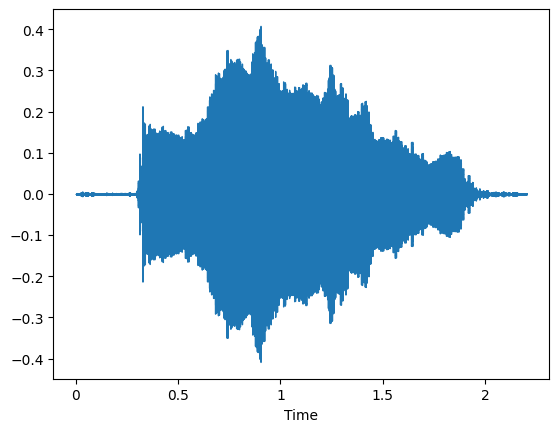

In [3]:
# Visualize audio
librosa.display.waveshow(audio, sr=sr)

#가로축은 시간, 세로축은 공기압력과 관련(진폭, amplitude). 클수록 큰 소리
#특정 사인파가 반복되는 패턴을 보임. >> 주기(cycle). 초당 주기의 수 = 주파수. 단위 Hz
#스펙트럼: 복잡합 파형은 여러 주파수와 진폭을 지닌 사인파의 조합을 통해 나타남. 진폭이 클수록 많이 관여
#푸리에 변환을 통해 소리로부터 스펙트럼 출력 가능
#기초 주파수 막대 그래프로 나타남 가로 주파수, 세로 진폭. 나타나는 주파수는 서로 하모닉(배수 관계)
#스펙트로그램: 흑백 사진 그거. 스펙트럼을 시간대 별로 쌓은 그림. short time 푸리에변환 (STFT)
#3차원 스펙트로그램을 2차원으로 나타내면 흑백으로 진폭을 나타냄. 가로 시간, 세로 주파수. >> 모음 분석에 용이


## 2. Spectrogram

In [ ]:
# Pre-emphasis
pre_audio = librosa.effects.preemphasis(audio)

In [ ]:
# Short-time Fourier Transform (STFT)
n_fft = 2048
win_length = int(sr * 0.005)
hop_length = int(sr * 0.001)

stft_result = librosa.stft(
    pre_audio,
    n_fft=n_fft,
    win_length=win_length,
    hop_length=hop_length
)

In [ ]:
# Amplitude -> dB
magnitude = np.abs(stft_result)
spec_db = librosa.amplitude_to_db(magnitude, ref=np.max(magnitude))

In [ ]:
# Visualize spectrogram
plt.figure(figsize=(13, 3))

librosa.display.specshow(
    spec_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="linear",
    cmap="gray_r",
    vmin=-40,
    vmax=0
)

plt.ylim(0, 5000)
plt.xlim(0, len(audio) / sr)
plt.grid(axis="y")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.show()